# Model 1: Bayesian Linear Regression

This notebook recreates the first price elasticity model:

```text
quantity ~ unit_price
```

The goal is not to build the best model yet. The goal is to establish the Bayesian workflow: prepare the data, define priors, sample the posterior, check diagnostics, and create posterior predictive intervals.


## Notebook setup

These notebooks live one folder below the project root, so the first code cell adds the project root to `sys.path`. That lets us reuse `utils.data_loader.load_sales_data()` without duplicating data loading logic.

The sampling defaults are intentionally smaller than the script defaults so the notebooks are easier to run interactively. Increase `DRAWS`, `TUNE`, or `CHAINS` when you want more stable final inference.


In [14]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep cache and PyTensor compiler behavior predictable in notebooks.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib-cache"))
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")

FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

RANDOM_SEED = 123
# DRAWS = 50
# TUNE = 50
# CHAINS = 1
# CORES = 1
# TARGET_ACCEPT = 0.95

DRAWS = 2000
TUNE = 1000
CHAINS = 4
CORES = 1
TARGET_ACCEPT = 0.95


In [15]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from utils.data_loader import load_sales_data

az.style.use("arviz-whitegrid")

In [ ]:
sales_df = load_sales_data()
sales_df.head()

,product,quantity,unit_price
0,Standard iPhone Case,444,38.79
1,Standard iPhone Case,477,36.12
2,Standard iPhone Case,656,27.62
3,Standard iPhone Case,507,36.48
4,Standard iPhone Case,513,37.50


In [17]:
sales_df.info()
sales_df.describe(include="all")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   product     197 non-null    category
 1   quantity    197 non-null    int64   
 2   unit_price  197 non-null    float64 
dtypes: category(1), float64(1), int64(1)
memory usage: 3.5 KB


,product,quantity,unit_price
count,197,197.000000,197.000000
unique,2,NaN,NaN
top,Standard iPhone Case,NaN,NaN
freq,100,NaN,NaN
mean,NaN,440.137056,46.512437
std,NaN,115.559449,14.660253
min,NaN,160.000000,18.170000
25%,NaN,368.000000,35.030000
50%,NaN,444.000000,39.400000
75%,NaN,518.000000,60.630000


A quick plot helps anchor the modeling problem. We are looking for the relationship between `unit_price` and `quantity`, while remembering that products may have different demand curves.


In [18]:
# Task: do a best fit plot using ggplot

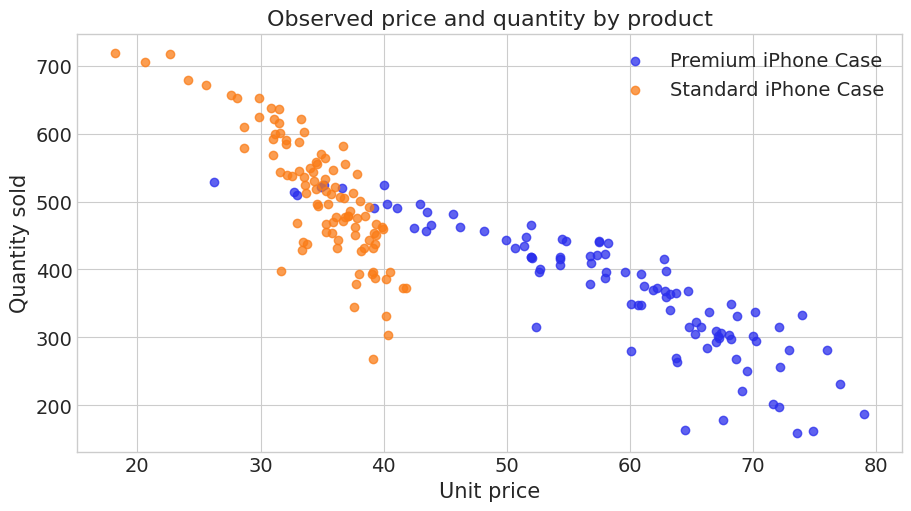

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
for product, group in sales_df.groupby("product", observed=True):
    ax.scatter(group["unit_price"], group["quantity"], alpha=0.75, label=str(product))
ax.set_xlabel("Unit price")
ax.set_ylabel("Quantity sold")
ax.set_title("Observed price and quantity by product")
ax.legend()
plt.show()


Note: Premium phones curves are a little bit flatter than the standard case

In [20]:
def standardise(values):
    values = np.asarray(values, dtype=float)
    mean = float(np.mean(values))
    std = float(np.std(values))
    if std == 0:
        raise ValueError("Cannot standardise a variable with zero variance.")
    return (values - mean) / std, mean, std


def prediction_summary(posterior_predictive, original_data, var_name="quantity_obs"):
    draws = posterior_predictive.posterior_predictive[var_name].values
    draws = draws.reshape(-1, draws.shape[-1])
    summary = pd.DataFrame({
        ".pred": np.mean(draws, axis=0),
        ".pred_lower_95": np.quantile(draws, 0.025, axis=0),
        ".pred_lower_66": np.quantile(draws, 0.17, axis=0),
        ".pred_upper_66": np.quantile(draws, 0.83, axis=0),
        ".pred_upper_95": np.quantile(draws, 0.975, axis=0),
    })
    return pd.concat([original_data.reset_index(drop=True), summary], axis=1)


def plot_predictions(predictions, title, facet=False):
    if not facet:
        plot_data = predictions.sort_values("unit_price")
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20, label="95% interval")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35, label="66% interval")
        for product, group in plot_data.groupby("product", observed=True):
            ax.scatter(group["unit_price"], group["quantity"], alpha=0.70, label=str(product))
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black", label="Posterior predictive mean")
        ax.set_xlabel("Unit price")
        ax.set_ylabel("Quantity sold")
        ax.set_title(title)
        ax.legend(fontsize=8)
        plt.show()
        return

    products = list(predictions["product"].cat.categories if hasattr(predictions["product"], "cat") else sorted(predictions["product"].unique()))
    fig, axes = plt.subplots(1, len(products), figsize=(6 * len(products), 5), sharey=True)
    if len(products) == 1:
        axes = [axes]
    for ax, product in zip(axes, products):
        plot_data = predictions[predictions["product"] == product].sort_values("unit_price")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20)
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35)
        ax.scatter(plot_data["unit_price"], plot_data["quantity"], alpha=0.70)
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black")
        ax.set_title(str(product))
        ax.set_xlabel("Unit price")
    axes[0].set_ylabel("Quantity sold")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


Model 1: Linear (Bad)
- Linear (bad for nonlinear problem)
- No hierarchy (Bad)

## Model idea

The linear model says expected quantity changes by a constant amount each time price increases by one standard deviation:

```text
quantity_i ~ Normal(mu_i, sigma)
mu_i = alpha + beta * unit_price_scaled_i
```

`alpha` is the baseline expected quantity, `beta` is the global price effect, and `sigma` is residual noise. Because the predictor is standardised, the sampler sees a numerically friendlier version of price while plots still use the original price scale.


In [21]:
unit_price_raw = sales_df["unit_price"].to_numpy(dtype=float)
quantity = sales_df["quantity"].to_numpy(dtype=float)
unit_price_scaled, price_mean, price_std = standardise(unit_price_raw)
price_mean, price_std

(46.512436548223356, 14.62299680939575)

In [22]:
with pm.Model() as model_1:
    unit_price_data = pm.Data("unit_price_scaled", unit_price_scaled)

    alpha = pm.Normal("alpha", mu=float(np.mean(quantity)), sigma=float(np.std(quantity) * 2))
    beta = pm.Normal("beta", mu=0, sigma=float(np.std(quantity)))
    sigma = pm.HalfNormal("sigma", sigma=float(np.std(quantity)))

    mu = alpha + beta * unit_price_data
    quantity_obs = pm.Normal("quantity_obs", mu=mu, sigma=sigma, observed=quantity)

    trace_1 = pm.sample(
        draws=DRAWS,
        tune=TUNE,
        chains=CHAINS,
        cores=CORES,
        target_accept=TARGET_ACCEPT,
        random_seed=RANDOM_SEED,
        return_inferencedata=True,
    )
    ppc_1 = pm.sample_posterior_predictive(trace_1, var_names=["quantity_obs"], random_seed=RANDOM_SEED, return_inferencedata=True)


/Users/aryamathew/Documents/learn-business-datascience/hierarchical-models/bayesian_price_elasticity/.venv/lib/python3.9/site-packages/pymc/data.py:434: UserWarning: The `mutable` kwarg was not specified. Before v4.1.0 it defaulted to `pm.Data(mutable=True)`, which is equivalent to using `pm.MutableData()`. In v4.1.0 the default changed to `pm.Data(mutable=False)`, equivalent to `pm.ConstantData`. Use `pm.ConstantData`/`pm.MutableData` or pass `pm.Data(..., mutable=False/True)` to avoid this warning.
  warnings.warn(
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, beta, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 639 seconds.
Sampling: [quantity_obs]


## Diagnostics

For a quick smoke test, this notebook uses one short chain, so `r_hat` will show as missing. For a final model, increase `CHAINS`, `DRAWS`, and `TUNE`; then `r_hat` should be close to 1 and effective sample sizes should not be tiny.


In [24]:
az.summary(trace_1, var_names=["alpha", "beta", "sigma"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,440.236,4.212,432.458,448.241,0.048,0.034,7838.0,5585.0,1.0
beta,-99.003,4.221,-106.842,-90.941,0.050,0.035,7258.0,5059.0,1.0
sigma,59.323,3.055,53.929,65.281,0.035,0.025,7522.0,5431.0,1.0


In [ ]:
trace_1

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data
	> constant_data

/var/folders/qm/sbby5mpx22g9cm6655g9bwcw0000gn/T/ipykernel_95858/2955998568.py:3: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


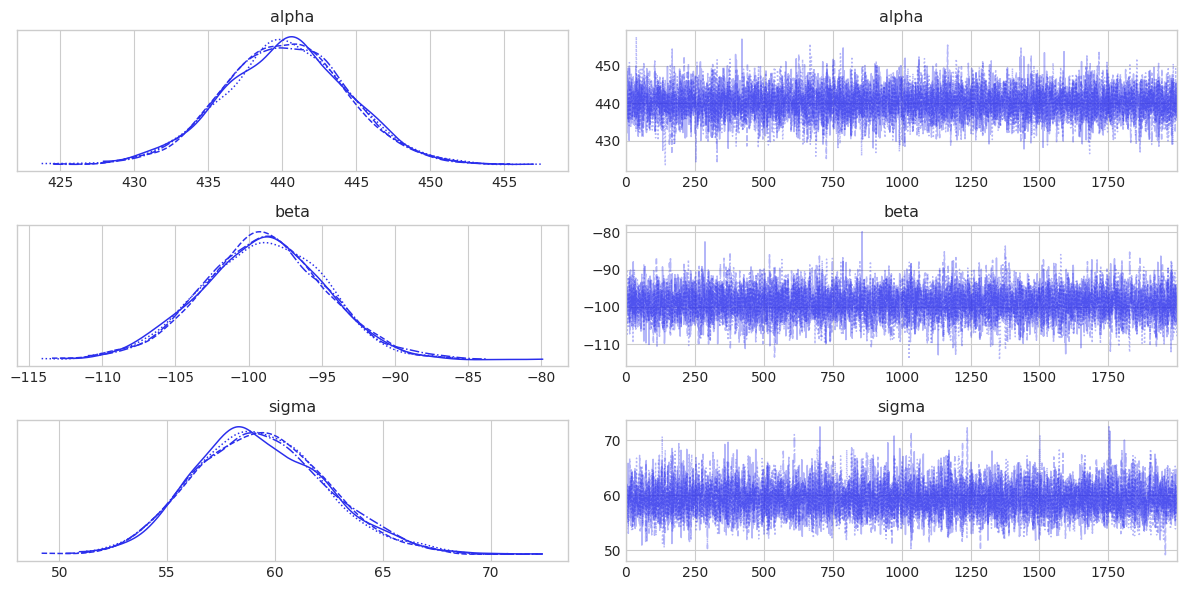

In [ ]:
# histogram of parameters
# alpha: posterior distribution of the intercept, baseline expected quantity
# beta: posterior distribution of the price effect. 
# In your current model this is for standardised unit price, so it means change in quantity for a 1 standard deviation increase in price.
az.plot_trace(trace_1, var_names=["alpha", "beta", "sigma"])
plt.tight_layout()
plt.show()

## Posterior predictions

Posterior predictive intervals show uncertainty in future observed quantities, not just uncertainty in the mean line. This is why the bands are wider than a fitted regression line would be.


In [ ]:
# 95% and 66% confidence range-
predictions_1 = prediction_summary(ppc_1, sales_df)
predictions_1.head()

,product,quantity,unit_price,.pred,.pred_lower_95,.pred_lower_66,.pred_upper_66,.pred_upper_95
0,Standard iPhone Case,444,38.79,492.418345,371.573248,435.614901,549.641322,609.579511
1,Standard iPhone Case,477,36.12,509.539231,390.061669,451.654965,566.769248,626.508036
2,Standard iPhone Case,656,27.62,568.601447,448.705820,510.860210,627.005222,684.446368
3,Standard iPhone Case,507,36.48,507.592216,392.439252,450.742392,564.444012,626.139890
4,Standard iPhone Case,513,37.50,501.015437,382.707652,444.594522,557.317948,615.353456


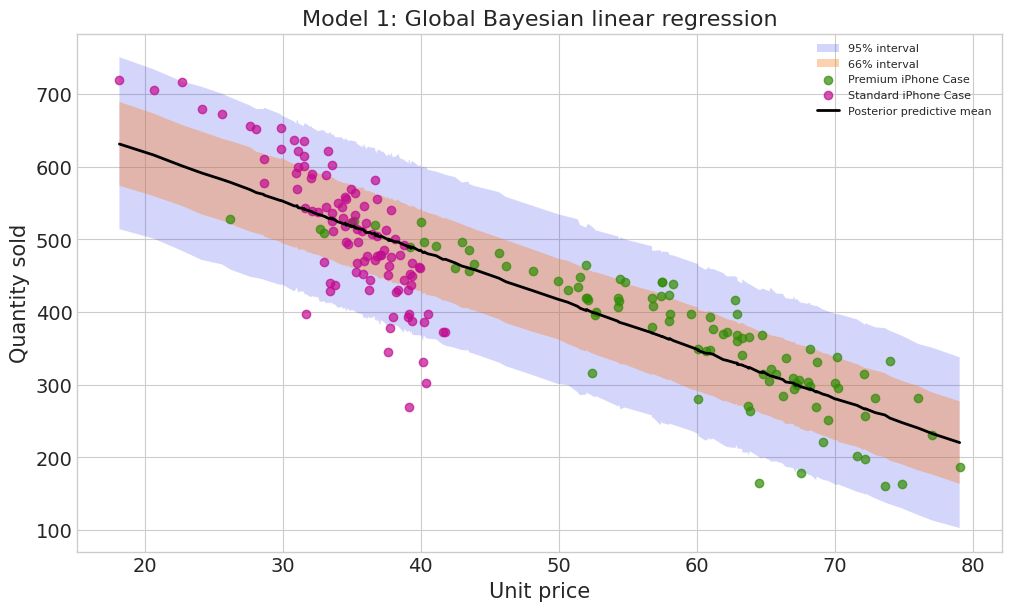

In [ ]:
plot_predictions(predictions_1, "Model 1: Global Bayesian linear regression")

Cons: The data is non-linear, but the model is linear

- We now have 66% and 95% credibility interval
- it gets wider as the variance in data increases

In [ ]:
trace_1.to_netcdf(MODELS_DIR / "notebook_model1_linear_trace.nc")
predictions_1.to_csv(MODELS_DIR / "notebook_model1_linear_predictions.csv", index=False)
print("Saved notebook Model 1 outputs.")

Saved notebook Model 1 outputs.


## Interpretation

This model is useful as a baseline, but it is intentionally restrictive. It assumes one straight price-demand relationship for every product. If demand curves bend or if products behave differently, this model will average those patterns into one line.
